
# Dataset
The Palmer Penguins dataset contains measurements of penguins from different species and islands.
  

In [10]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

url = "https://huggingface.co/datasets/SIH/palmer-penguins/resolve/main/penguins.csv"
df = pd.read_csv(url)
df_copy = df.copy()

print(df_copy.head().to_string(index=False))


species    island  bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g    sex  year
 Adelie Torgersen            39.1           18.7              181.0       3750.0   male  2007
 Adelie Torgersen            39.5           17.4              186.0       3800.0 female  2007
 Adelie Torgersen            40.3           18.0              195.0       3250.0 female  2007
 Adelie Torgersen             NaN            NaN                NaN          NaN    NaN  2007
 Adelie Torgersen            36.7           19.3              193.0       3450.0 female  2007



#Understanding the Dataset
In this section the dataset was inspected to understand its structure.


In [11]:
print("Rows and Columns:",df.shape)
print("Column Names:")
print(df.columns)

print("Data Types:")
print(df.dtypes)

df.info()

print("Summary Statistics:")
display(df.describe())

print("Species Count:")
print(df["species"].value_counts())


Rows and Columns: (344, 8)
Column Names:
Index(['species', 'island', 'bill_length_mm', 'bill_depth_mm',
       'flipper_length_mm', 'body_mass_g', 'sex', 'year'],
      dtype='object')
Data Types:
species               object
island                object
bill_length_mm       float64
bill_depth_mm        float64
flipper_length_mm    float64
body_mass_g          float64
sex                   object
year                   int64
dtype: object
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    object 
 7   year            

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,year
count,342.000000,342.000000,342.000000,342.000000,344.000000
mean,43.921930,17.151170,200.915205,4201.754386,2008.029070
std,5.459584,1.974793,14.061714,801.954536,0.818356
min,32.100000,13.100000,172.000000,2700.000000,2007.000000
25%,39.225000,15.600000,190.000000,3550.000000,2007.000000
50%,44.450000,17.300000,197.000000,4050.000000,2008.000000
75%,48.500000,18.700000,213.000000,4750.000000,2009.000000
max,59.600000,21.500000,231.000000,6300.000000,2009.000000


Species Count:
species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64



#Checking Data Quality
Missing values are checked in this section.



In [12]:

missing_counts = df.isnull().sum()
display(missing_counts)

missing_percent = (df.isnull().sum() / len(df)) * 100
display(missing_percent.round(2))

rows_with_missing = df[df.isnull().any(axis=1)]
display(rows_with_missing.head())


,0
species,0
island,0
bill_length_mm,2
bill_depth_mm,2
flipper_length_mm,2
body_mass_g,2
sex,11
year,0


,0
species,0.00
island,0.00
bill_length_mm,0.58
bill_depth_mm,0.58
flipper_length_mm,0.58
body_mass_g,0.58
sex,3.20
year,0.00


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
8,Adelie,Torgersen,34.1,18.1,193.0,3475.0,NaN,2007
9,Adelie,Torgersen,42.0,20.2,190.0,4250.0,NaN,2007
10,Adelie,Torgersen,37.8,17.1,186.0,3300.0,NaN,2007
11,Adelie,Torgersen,37.8,17.3,180.0,3700.0,NaN,2007



#Descriptive statistics



In [15]:
body_mass = df["body_mass_g"].dropna()

print("Mean:", round(np.mean(body_mass), 2))
print("Median:", round(np.median(body_mass), 2))
print("Minimum:", round(body_mass.min(), 2))
print("Maximum:", round(body_mass.max(), 2))
print("Standard Deviation:", round(np.std(body_mass), 2))

print("Q1:", round(np.percentile(body_mass, 25), 2))
print("Q3:", round(np.percentile(body_mass, 75), 2))



Mean: 4201.75
Median: 4050.0
Minimum: 2700.0
Maximum: 6300.0
Standard Deviation: 800.78
Q1: 3550.0
Q3: 4750.0



#Scatter plot


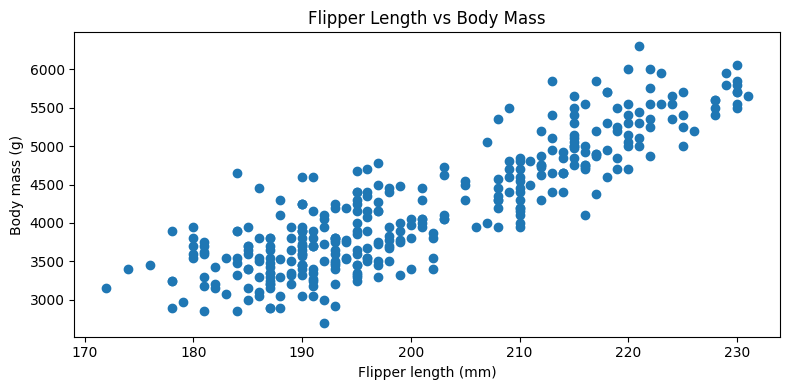

In [14]:
plot_data = df[["flipper_length_mm", "body_mass_g"]].dropna()

plt.figure(figsize=(8, 4))

plt.scatter(plot_data["flipper_length_mm"],
            plot_data["body_mass_g"])

plt.xlabel("Flipper length (mm)")
plt.ylabel("Body mass (g)")
plt.title("Flipper Length vs Body Mass")

plt.tight_layout()
plt.show()


#Comparison


In [8]:
mean_mass = df.groupby("species")["body_mass_g"].mean()

print("Mean Body Mass by Species:")
print(mean_mass.round(2))

median_mass = df.groupby("species")["body_mass_g"].median()

print("\nMedian Body Mass by Species:")
print(median_mass.round(2))


Mean Body Mass by Species:
species
Adelie       3700.66
Chinstrap    3733.09
Gentoo       5076.02
Name: body_mass_g, dtype: float64

Median Body Mass by Species:
species
Adelie       3700.0
Chinstrap    3700.0
Gentoo       5000.0
Name: body_mass_g, dtype: float64



#Investigating Potential Outliers


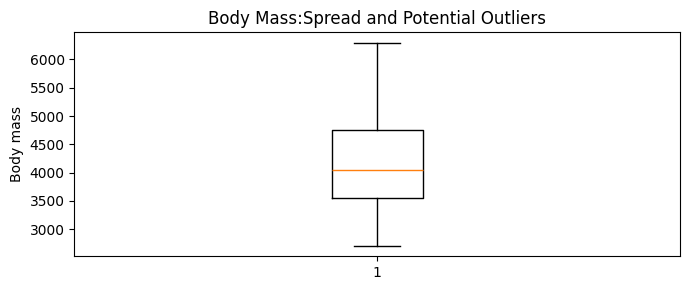

In [17]:
mass_values = df["body_mass_g"].dropna()

plt.figure(figsize=(7, 3))
plt.boxplot(mass_values)

plt.ylabel("Body mass")
plt.title("Body Mass:Spread and Potential Outliers")

plt.tight_layout()
plt.show()
